In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import polars.selectors as cs
import math
import seaborn as sns
from pathlib import Path

In [2]:
dataset_path = Path('../data/cfd/OFIQ')
df_list = []

for f in sorted(dataset_path.iterdir()):
    if f.is_file() and f.suffix == '.csv':
        temp = pl.read_csv(f, separator=';', infer_schema_length=None,)
        df_list.append(temp)

df = pl.concat(df_list, how='vertical_relaxed')
df.head(5)

Filename,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native,UnifiedQualityScore.scalar,BackgroundUniformity.scalar,IlluminationUniformity.scalar,LuminanceMean.scalar,LuminanceVariance.scalar,UnderExposurePrevention.scalar,OverExposurePrevention.scalar,DynamicRange.scalar,Sharpness.scalar,NoCompressionArtifacts.scalar,NaturalColour.scalar,SingleFacePresent.scalar,EyesOpen.scalar,MouthClosed.scalar,EyesVisible.scalar,MouthOcclusionPrevention.scalar,FaceOcclusionPrevention.scalar,InterEyeDistance.scalar,HeadSize.scalar,LeftwardCropOfFace.scalar,RightwardCropOfFace.scalar,MarginAboveTheFace.scalar,MarginBelowTheFace.scalar,HeadPoseYawFrontal.scalar,HeadPosePitchFrontal.scalar,HeadPoseRollFrontal.scalar,ExpressionNeutrality.scalar,NoHeadCoverings.scalar,assessment_time_in_ms,
str,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,str
"""/home/vramos/prove/cfd_all/ima…",24.46866,3.470554,0.832562,0.160287,0.009185,0.262809,0.000076,6.322717,49,0.972135,0.0,0.0,0.091912,0.115417,0.0,0.0,0.003066,341.103462,0.327847,4.034566,4.131325,1.406109,1.644011,0.987686,5.915962,-0.360723,-14591.978516,0.0,64,98,95,31,90,100,99,79,100,100,100,100,100,80,100,100,100,100,16,100,100,52,17,100,99,100,13,100,4266,null
"""/home/vramos/prove/cfd_all/ima…",24.744558,0.603806,0.836505,0.132863,0.012127,0.434961,0.00058,6.184551,48,0.951159,0.0,0.0,0.086876,0.10639,0.0,0.0,0.002601,361.016412,0.361468,3.875346,3.894737,1.294684,1.471818,-0.546339,10.803646,-0.045136,-14810.550781,0.0,66,99,95,21,97,100,95,77,100,100,100,100,100,83,100,100,100,100,29,100,100,26,4,100,96,100,12,100,4028,null
"""/home/vramos/prove/cfd_all/ima…",21.030891,1.011412,0.888889,0.149727,0.014539,0.398864,0.000816,6.443181,49,0.972673,0.0,0.0,0.053393,0.150023,0.0,0.0,0.001301,352.269381,0.407461,3.985538,3.957131,1.149971,1.304252,2.144223,3.011373,0.29784,-14497.498047,0.0,32,99,97,27,99,100,92,81,100,100,100,100,97,70,100,100,100,100,60,100,100,8,1,100,100,100,13,100,4445,null
"""/home/vramos/prove/cfd_all/ima…",26.707853,28.183237,0.878028,0.128057,0.012872,0.459718,0.004663,5.897033,50,0.966662,0.0,0.0,0.080851,0.13554,0.0,0.0,0.004134,360.200111,0.408066,3.856192,3.928374,1.145412,1.305171,0.055048,3.146702,-0.538559,-15726.135742,0.0,81,86,96,19,98,100,68,74,100,100,100,100,100,75,100,100,100,100,60,100,100,7,1,100,100,100,10,100,4625,null
"""/home/vramos/prove/cfd_all/ima…",23.728788,3.151139,0.587191,0.353074,0.012493,0.045021,0.000018,6.743121,46,0.991112,0.0,0.0,0.122334,0.11979,0.0,0.0,0.003695,371.126639,0.366499,3.791571,3.794266,1.202221,1.526201,0.845368,1.853598,-2.179887,-10618.723633,0.0,57,98,85,96,97,100,100,84,100,100,100,100,100,79,100,100,100,100,32,100,100,12,6,100,100,100,25,100,4315,null


In [3]:
df = df.with_columns(
    pl.col([
        'UnifiedQualityScore.native',
        'UnderExposurePrevention.native',
        'OverExposurePrevention.native',
        'InterEyeDistance.native',
        'Sharpness.native'
    ]).cast(pl.Float64, strict=False)
)

In [4]:
df.select(pl.col(pl.Float32,pl.Float64).is_nan().sum())

UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


#### Data cleaning

In [5]:
df = df.filter(
    ~pl.any_horizontal(pl.col(pl.Float32, pl.Float64).is_nan())\
)

In [6]:
df.select(pl.col(pl.Float32,pl.Float64).is_nan().sum())

UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [7]:
native = df.select(cs.ends_with('.native'))
scalar = df.select(cs.ends_with('.scalar'))

#### Data distribution

In [8]:
def create_histograms(df, n_cols=4, bins=40, clip=(1, 99), drop_errors=True):
    n_rows = math.ceil(df.shape[1] / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.5 * n_rows))
    axes = np.array(axes).flatten()

    for ax, name in zip(axes, df.columns):
        values = df[name].drop_nulls().to_numpy().astype(float)
        values = values[~np.isnan(values)]
        if drop_errors:
            values = values[values != -1]          
        if len(values) == 0:
            ax.set_title(f"{name} (vuota)")
            continue
        lo, hi = np.percentile(values, clip)
        if lo == hi:                              
            lo, hi = values.min(), values.max() + 1e-9
        ax.hist(values, bins=bins, range=(lo, hi), edgecolor="white", linewidth=0.4)
        ax.set_title(name, fontsize=9)

    for ax in axes[len(df.columns):]:
        ax.set_visible(False)                

    fig.tight_layout()
    return fig

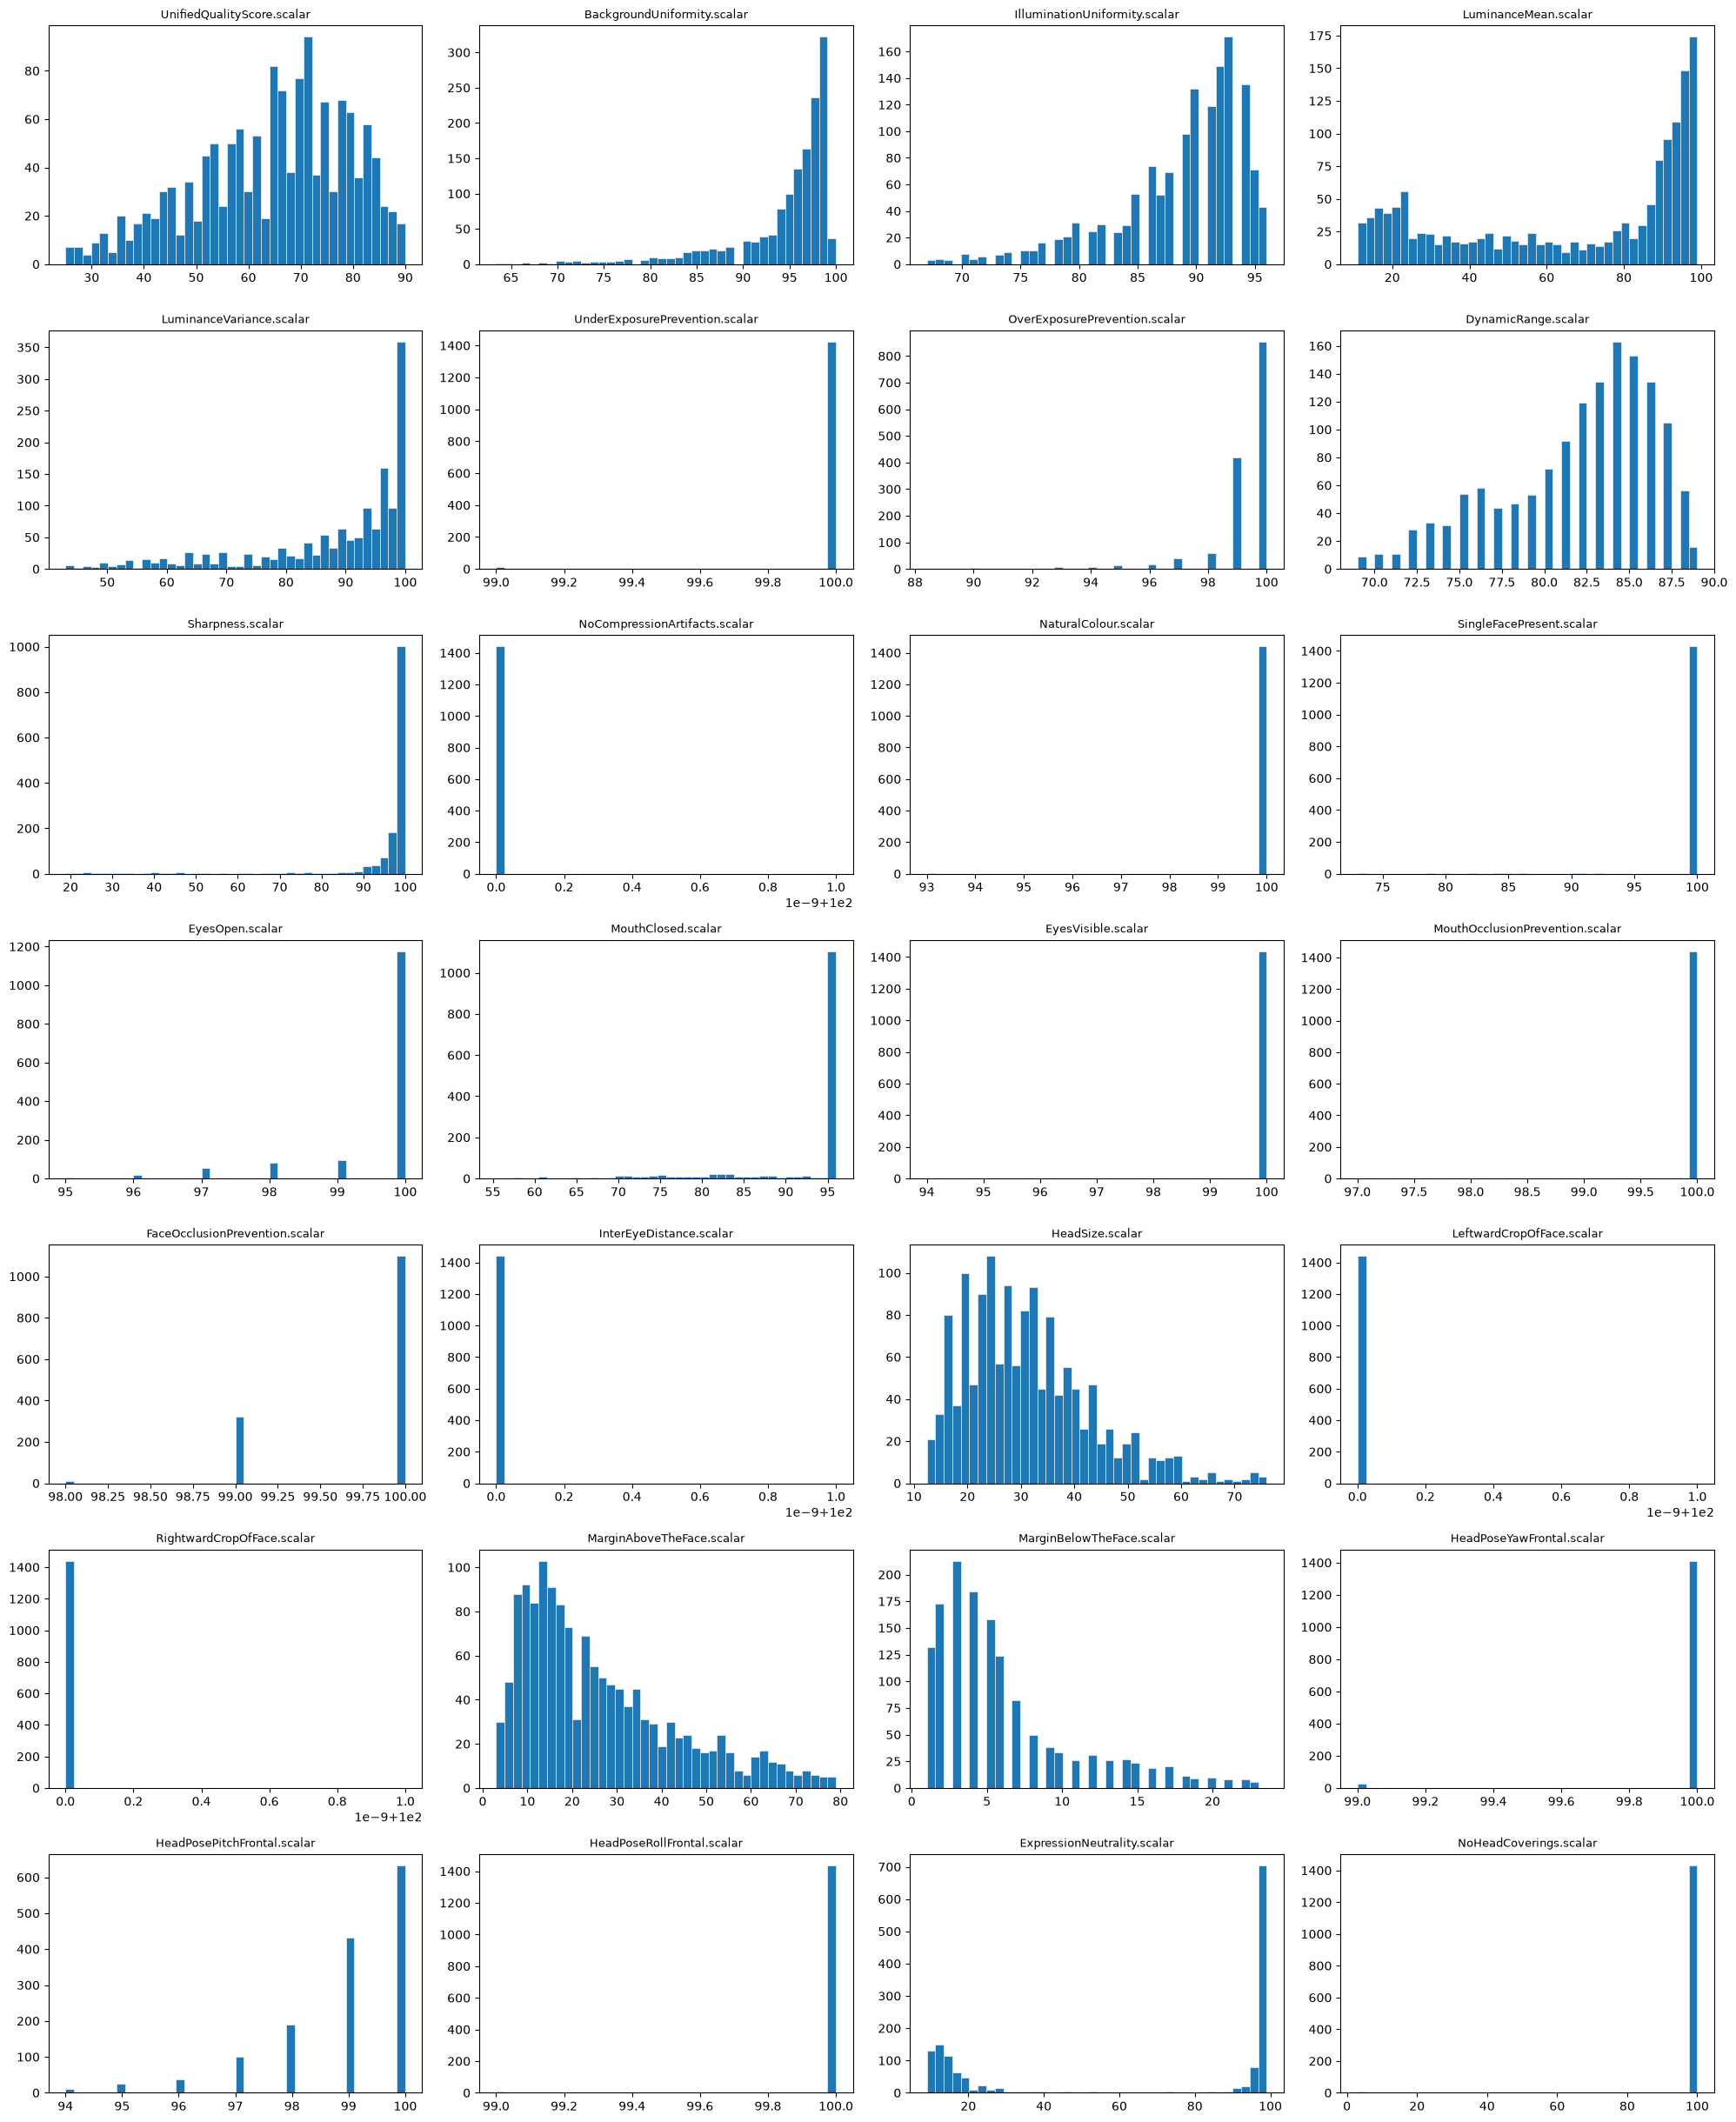

In [9]:
create_histograms(scalar);

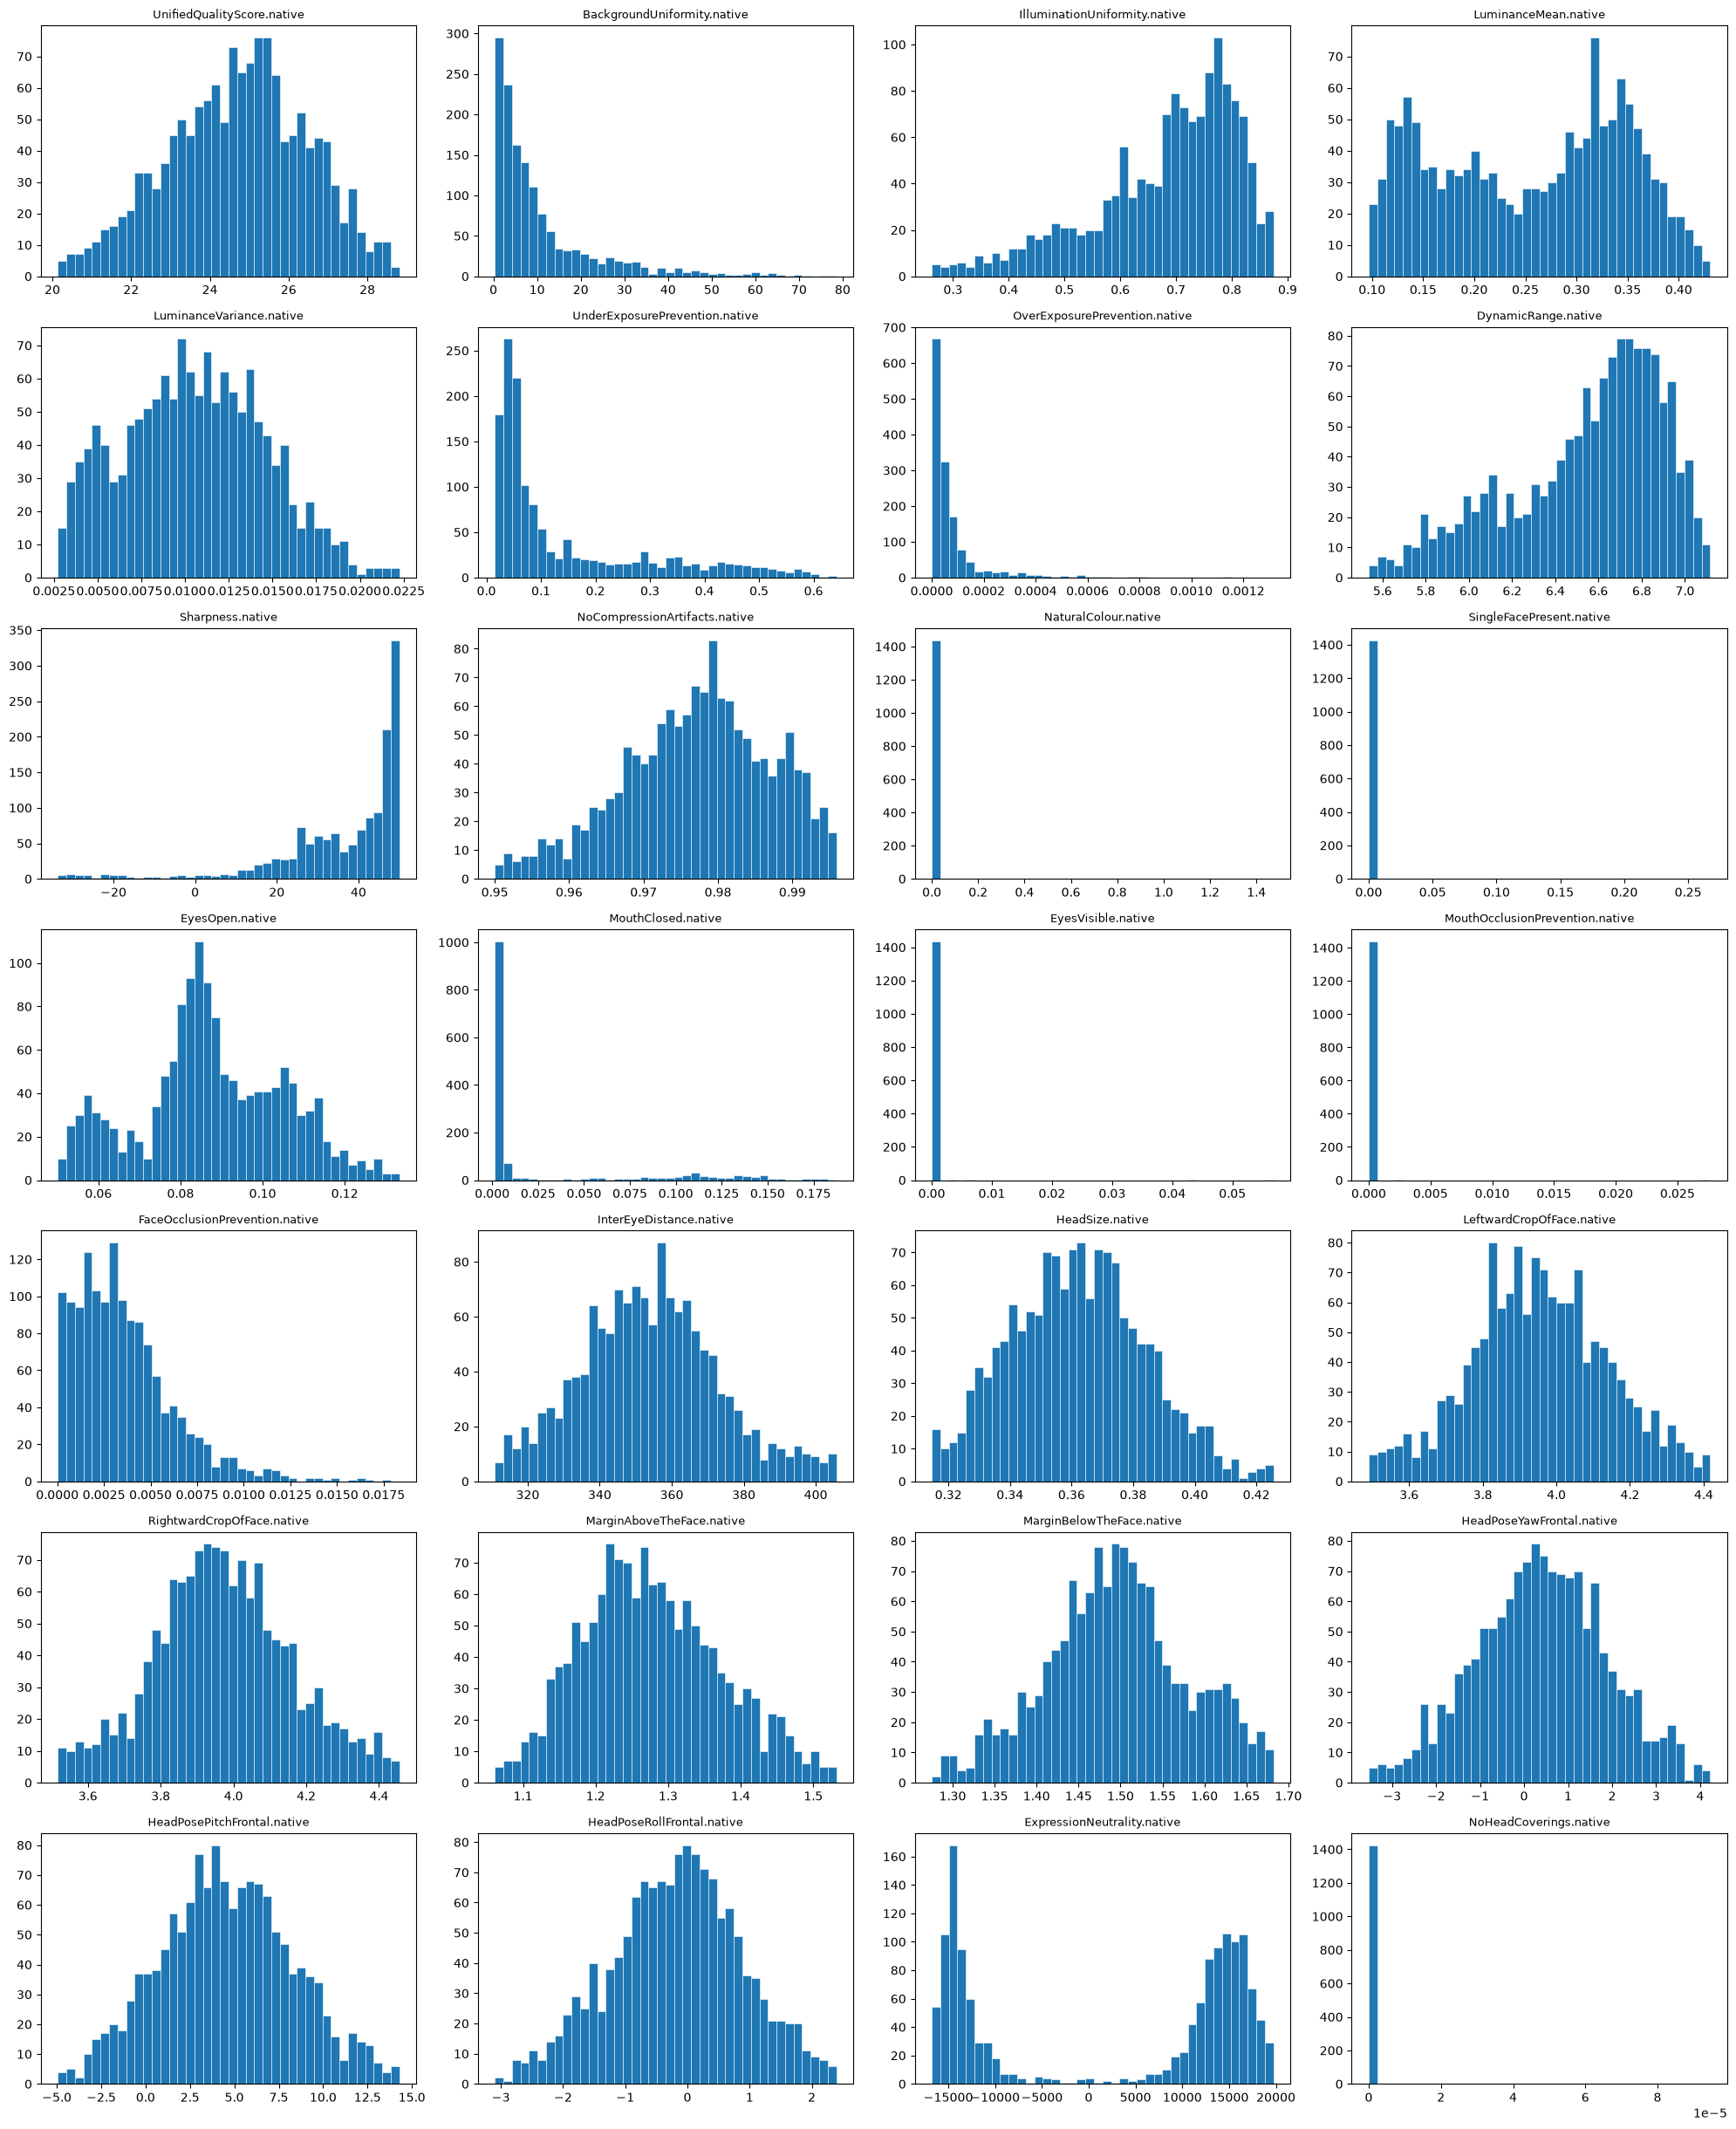

In [10]:
create_histograms(native);

#### Mean and Variabilty of the data

In [11]:
df_describe = native.describe()
mean = df_describe.filter(pl.col('statistic') == 'mean')
median = df_describe.filter(pl.col('statistic') == '50%')

In [12]:
df_describe

statistic,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0,1441.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",24.703754,11.845716,0.677756,0.256842,0.010605,0.149566,0.000097,6.538645,34.991672,0.976983,0.001088,0.00129,0.087556,0.029123,0.000081,0.000021,0.003864,354.072186,0.36227,3.954864,3.973192,1.277747,1.495191,0.391345,4.581034,-0.181473,2521.655169,0.002078
"""std""",1.889431,17.464977,0.138598,0.09427,0.004326,0.160548,0.000314,0.374094,17.838627,0.010569,0.038871,0.014495,0.018819,0.050896,0.001899,0.00073,0.004314,20.488476,0.023462,0.200494,0.202161,0.102174,0.089562,1.60106,4.060193,1.144735,14133.680183,0.027955
"""min""",18.116341,0.082656,0.147842,0.06734,0.00186,0.006008,0.0,5.210779,-48.0,0.930651,0.0,0.0,0.023607,0.0,0.0,0.0,0.0,296.29901,0.290487,3.348596,3.394562,1.005073,1.221001,-6.06095,-9.48334,-4.374299,-18646.224609,0.0
"""25%""",23.446945,2.64479,0.604671,0.169332,0.007503,0.04047,0.0,6.317781,29.0,0.970464,0.0,0.0,0.078048,0.002272,0.0,0.0,0.00159,340.216172,0.345656,3.82766,3.843911,1.208221,1.440678,-0.622954,1.944142,-0.875052,-13872.230469,0.0
"""50%""",24.792515,6.359703,0.709826,0.270751,0.010486,0.067098,0.000036,6.634206,42.0,0.977822,0.0,0.0,0.086441,0.003507,0.0,0.0,0.003113,353.404697,0.361758,3.949189,3.965748,1.269783,1.494924,0.401421,4.502175,-0.126709,11205.5625,0.0
"""75%""",25.99472,13.359933,0.778696,0.33718,0.013541,0.214585,0.000079,6.821467,47.0,0.984534,0.0,0.0,0.100922,0.009025,0.0,0.0,0.004897,366.256164,0.376892,4.081697,4.097715,1.341892,1.549106,1.423147,7.127624,0.558733,15154.298828,0.0
"""max""",31.728054,314.073142,0.895062,0.47362,0.032816,0.831255,0.00539,7.322018,50.0,0.998127,1.472562,0.267254,0.176135,0.247002,0.056785,0.02765,0.062331,423.129037,0.444487,4.62458,4.661805,1.74206,1.869556,5.420811,20.985079,4.620581,20803.167969,0.445434


In [13]:
mean

statistic,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""mean""",24.703754,11.845716,0.677756,0.256842,0.010605,0.149566,0.000097,6.538645,34.991672,0.976983,0.001088,0.00129,0.087556,0.029123,0.000081,0.000021,0.003864,354.072186,0.36227,3.954864,3.973192,1.277747,1.495191,0.391345,4.581034,-0.181473,2521.655169,0.002078


In [14]:
median

statistic,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""50%""",24.792515,6.359703,0.709826,0.270751,0.010486,0.067098,0.000036,6.634206,42.0,0.977822,0.0,0.0,0.086441,0.003507,0.0,0.0,0.003113,353.404697,0.361758,3.949189,3.965748,1.269783,1.494924,0.401421,4.502175,-0.126709,11205.5625,0.0


In [15]:
for c1, c2 in zip(mean.columns, median.columns):
    print(f"Column {c1}")
    print(f"Mean: {mean[c1].to_numpy().item()}")
    print(f"Median: {median[c1].to_numpy().item()}")
    print("==============")

Column statistic
Mean: mean
Median: 50%
Column UnifiedQualityScore.native
Mean: 24.703753634281743
Median: 24.792515
Column BackgroundUniformity.native
Mean: 11.845715970159606
Median: 6.359703
Column IlluminationUniformity.native
Mean: 0.6777557244968773
Median: 0.709826
Column LuminanceMean.native
Mean: 0.2568419118667592
Median: 0.270751
Column LuminanceVariance.native
Mean: 0.01060461623872311
Median: 0.010486
Column UnderExposurePrevention.native
Mean: 0.1495662366412214
Median: 0.067098
Column OverExposurePrevention.native
Mean: 9.729354614850797e-05
Median: 3.6e-05
Column DynamicRange.native
Mean: 6.538644757113115
Median: 6.634206
Column Sharpness.native
Mean: 34.99167244968772
Median: 42.0
Column NoCompressionArtifacts.native
Mean: 0.9769825794587089
Median: 0.977822
Column NaturalColour.native
Mean: 0.0010878639833448993
Median: 0.0
Column SingleFacePresent.native
Mean: 0.0012903601665510062
Median: 0.0
Column EyesOpen.native
Mean: 0.08755564399722415
Median: 0.086441
Column 

In [16]:
distance = df_describe.select(
    cs.numeric().filter(pl.col("statistic") == "max").first()
    - cs.numeric().filter(pl.col("statistic") == "min").first()
)

for col in distance.columns:
    print(col)
    print(f"Distanza: {distance[col].to_numpy().item()}")
    print("============")

UnifiedQualityScore.native
Distanza: 13.611713000000002
BackgroundUniformity.native
Distanza: 313.99048600000003
IlluminationUniformity.native
Distanza: 0.74722
LuminanceMean.native
Distanza: 0.40628
LuminanceVariance.native
Distanza: 0.030955999999999997
UnderExposurePrevention.native
Distanza: 0.825247
OverExposurePrevention.native
Distanza: 0.00539
DynamicRange.native
Distanza: 2.1112390000000003
Sharpness.native
Distanza: 98.0
NoCompressionArtifacts.native
Distanza: 0.06747599999999998
NaturalColour.native
Distanza: 1.472562
SingleFacePresent.native
Distanza: 0.267254
EyesOpen.native
Distanza: 0.15252800000000002
MouthClosed.native
Distanza: 0.247002
EyesVisible.native
Distanza: 0.056785
MouthOcclusionPrevention.native
Distanza: 0.02765
FaceOcclusionPrevention.native
Distanza: 0.062331
InterEyeDistance.native
Distanza: 126.83002699999997
HeadSize.native
Distanza: 0.15400000000000003
LeftwardCropOfFace.native
Distanza: 1.2759839999999998
RightwardCropOfFace.native
Distanza: 1.267243

In [17]:
std = df_describe.filter(pl.col('statistic') == 'std')

for col in std.columns:
    print(col)
    print(f"Varianza: {std[col].to_numpy().item()}")
    print("========================")

statistic
Varianza: std
UnifiedQualityScore.native
Varianza: 1.8894308272533833
BackgroundUniformity.native
Varianza: 17.464976641678547
IlluminationUniformity.native
Varianza: 0.1385982249982882
LuminanceMean.native
Varianza: 0.09427040540885494
LuminanceVariance.native
Varianza: 0.004325585523209226
UnderExposurePrevention.native
Varianza: 0.16054777540745355
OverExposurePrevention.native
Varianza: 0.0003135983595810571
DynamicRange.native
Varianza: 0.37409369778229545
Sharpness.native
Varianza: 17.838626552243703
NoCompressionArtifacts.native
Varianza: 0.01056942553807759
NaturalColour.native
Varianza: 0.03887094028203157
SingleFacePresent.native
Varianza: 0.014495052815244169
EyesOpen.native
Varianza: 0.01881877753768181
MouthClosed.native
Varianza: 0.050896099991529525
EyesVisible.native
Varianza: 0.0018991463290711696
MouthOcclusionPrevention.native
Varianza: 0.000730477823677627
FaceOcclusionPrevention.native
Varianza: 0.0043137773312855385
InterEyeDistance.native
Varianza: 20.4

In [18]:
def whisker_and_box_diagram(df):
    col = 4

    numeric_columns = [
        name for name in df.columns
        if df[name].dtype.is_numeric()
    ]
    row = math.ceil(len(numeric_columns) / col)
    fig, ax = plt.subplots(row, col, figsize=(20, 4 * row))
    ax = np.array(ax).flatten()

    for i, name in enumerate(numeric_columns):
        column = df[name].drop_nulls().to_numpy()

        if len(column) == 0:
            continue

        q1 = np.percentile(column, 25)
        med = np.percentile(column, 50)
        q3 = np.percentile(column, 75)

        iqr = q3 - q1

        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr

        fliers = column[
            (column < lower_limit) | (column > upper_limit)
        ]

        whislo = np.min(column[column >= lower_limit])
        whishi = np.max(column[column <= upper_limit])

        plt_data = [{
            'label': "",
            'whislo': whislo,
            'q1': q1,
            'med': med,
            'q3': q3,
            'whishi': whishi,
            'fliers': fliers
        }]

        ax[i].bxp(plt_data, orientation="horizontal")
        ax[i].set_title(name)
    for i in range(len(numeric_columns), len(ax)):
        fig.delaxes(ax[i])
    plt.show()

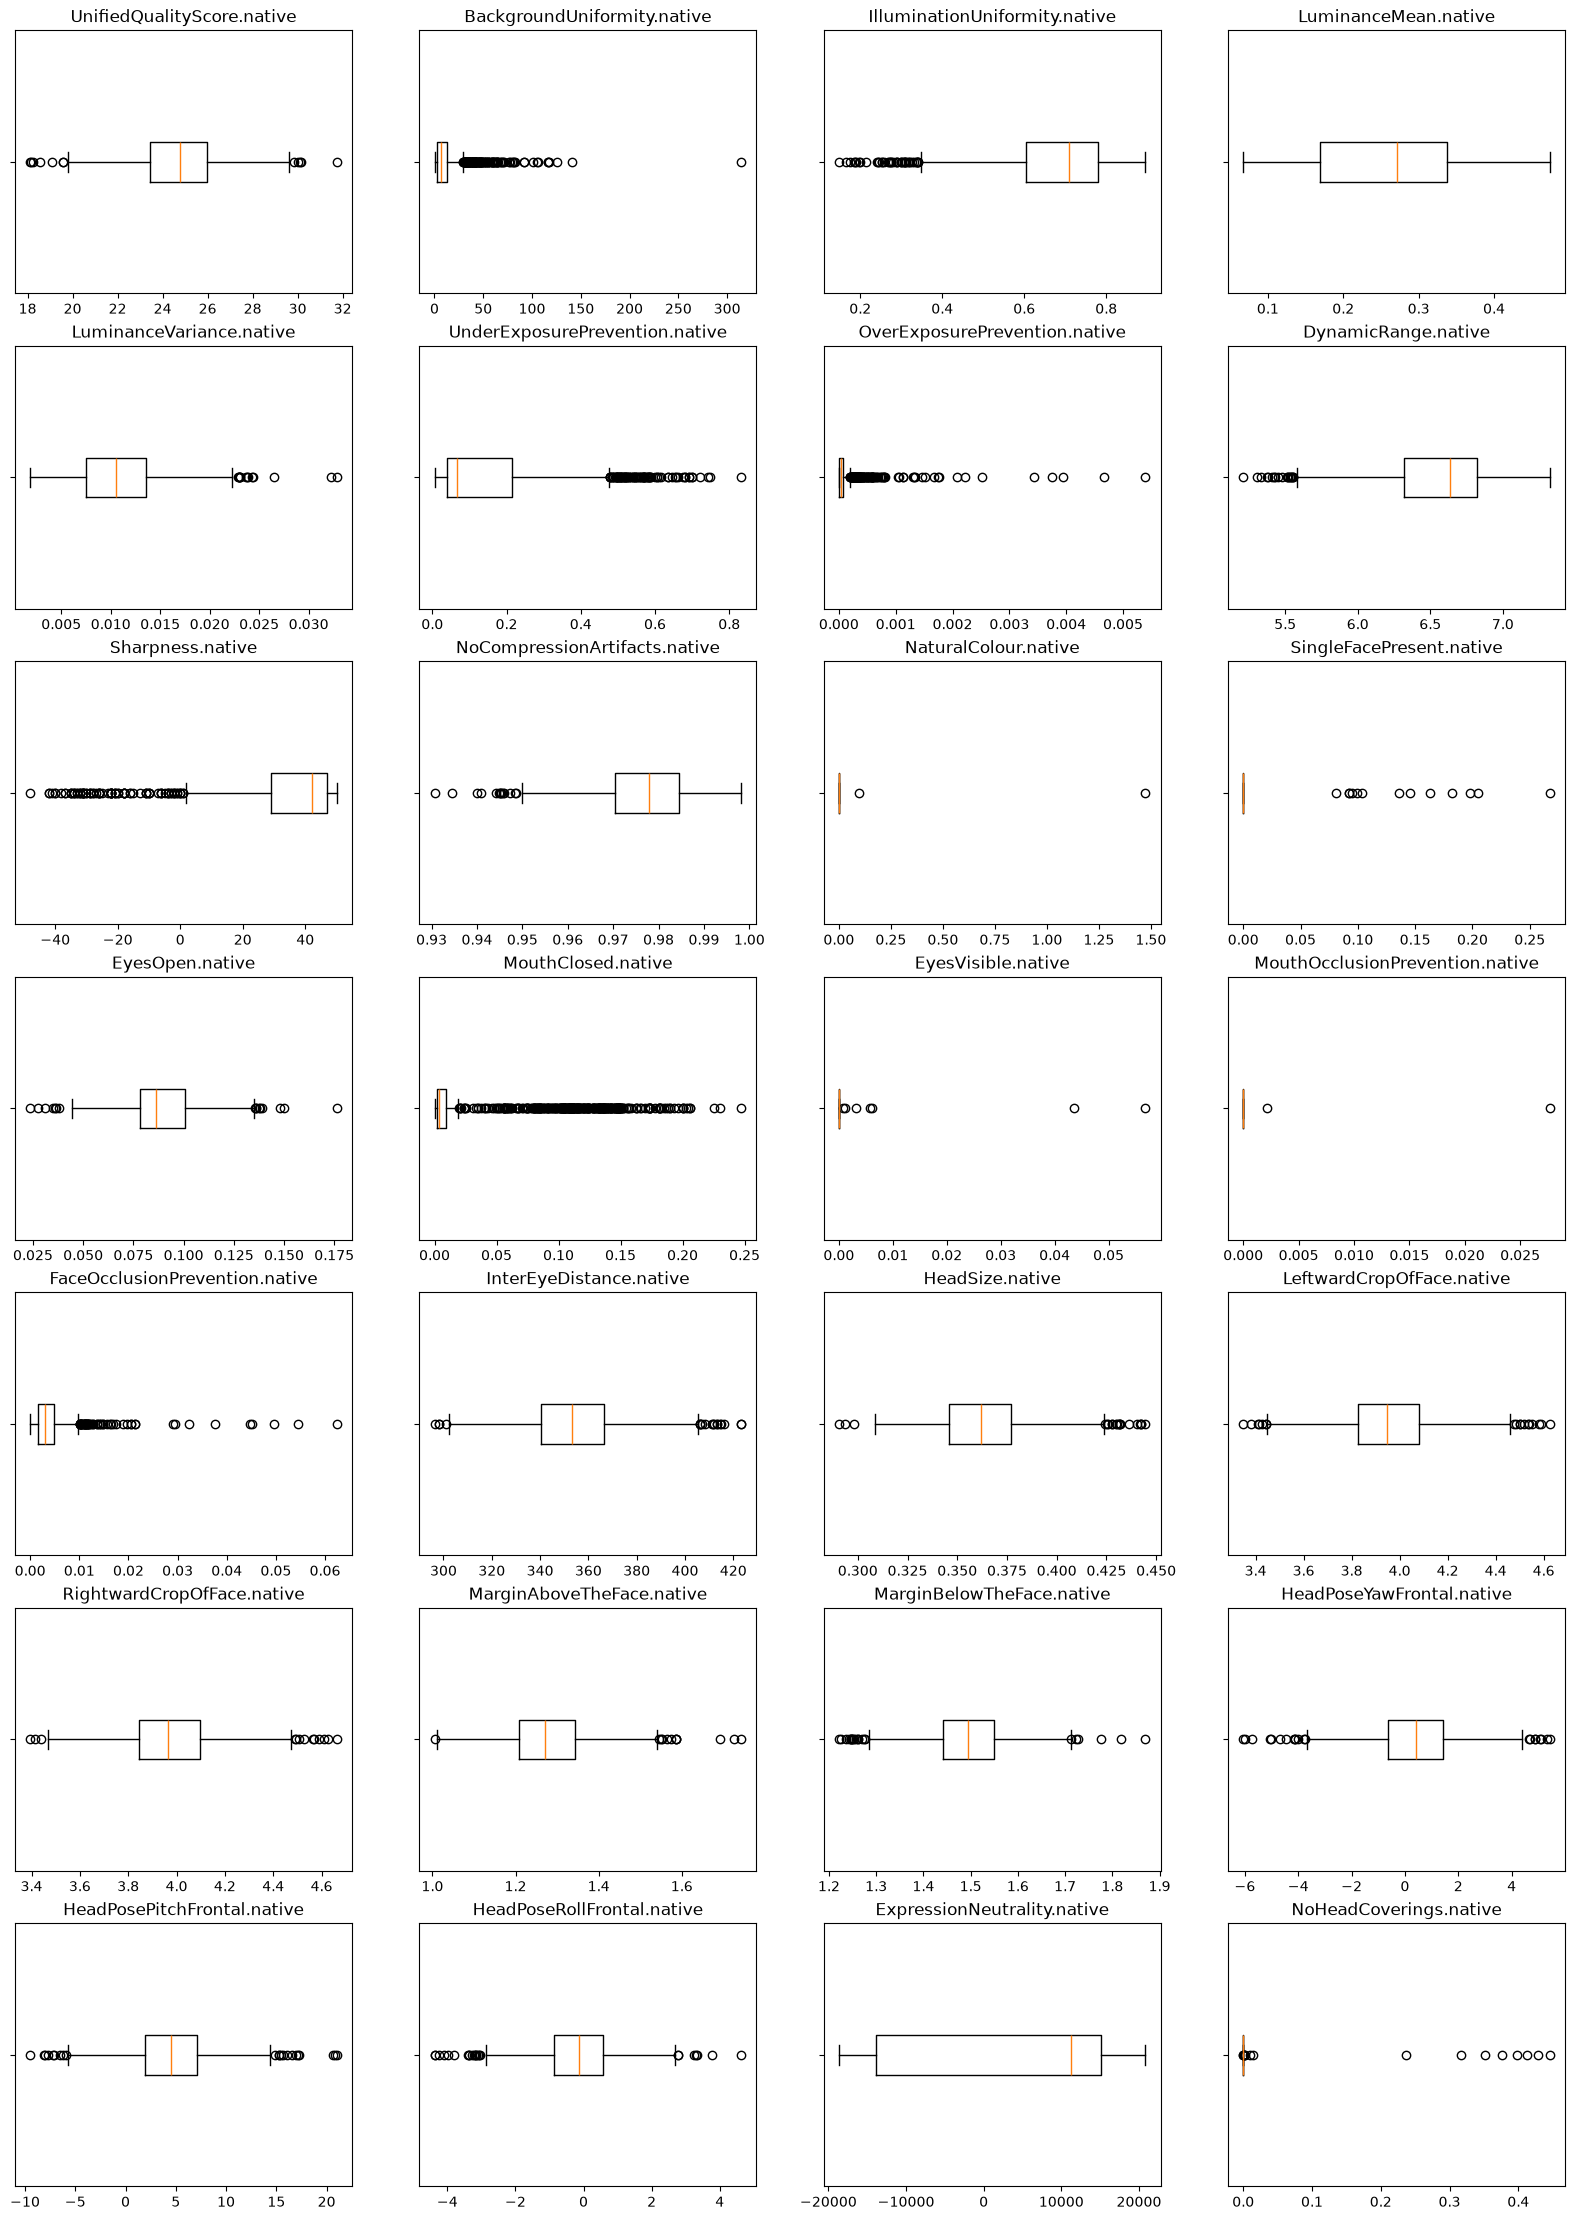

In [19]:
whisker_and_box_diagram(native)

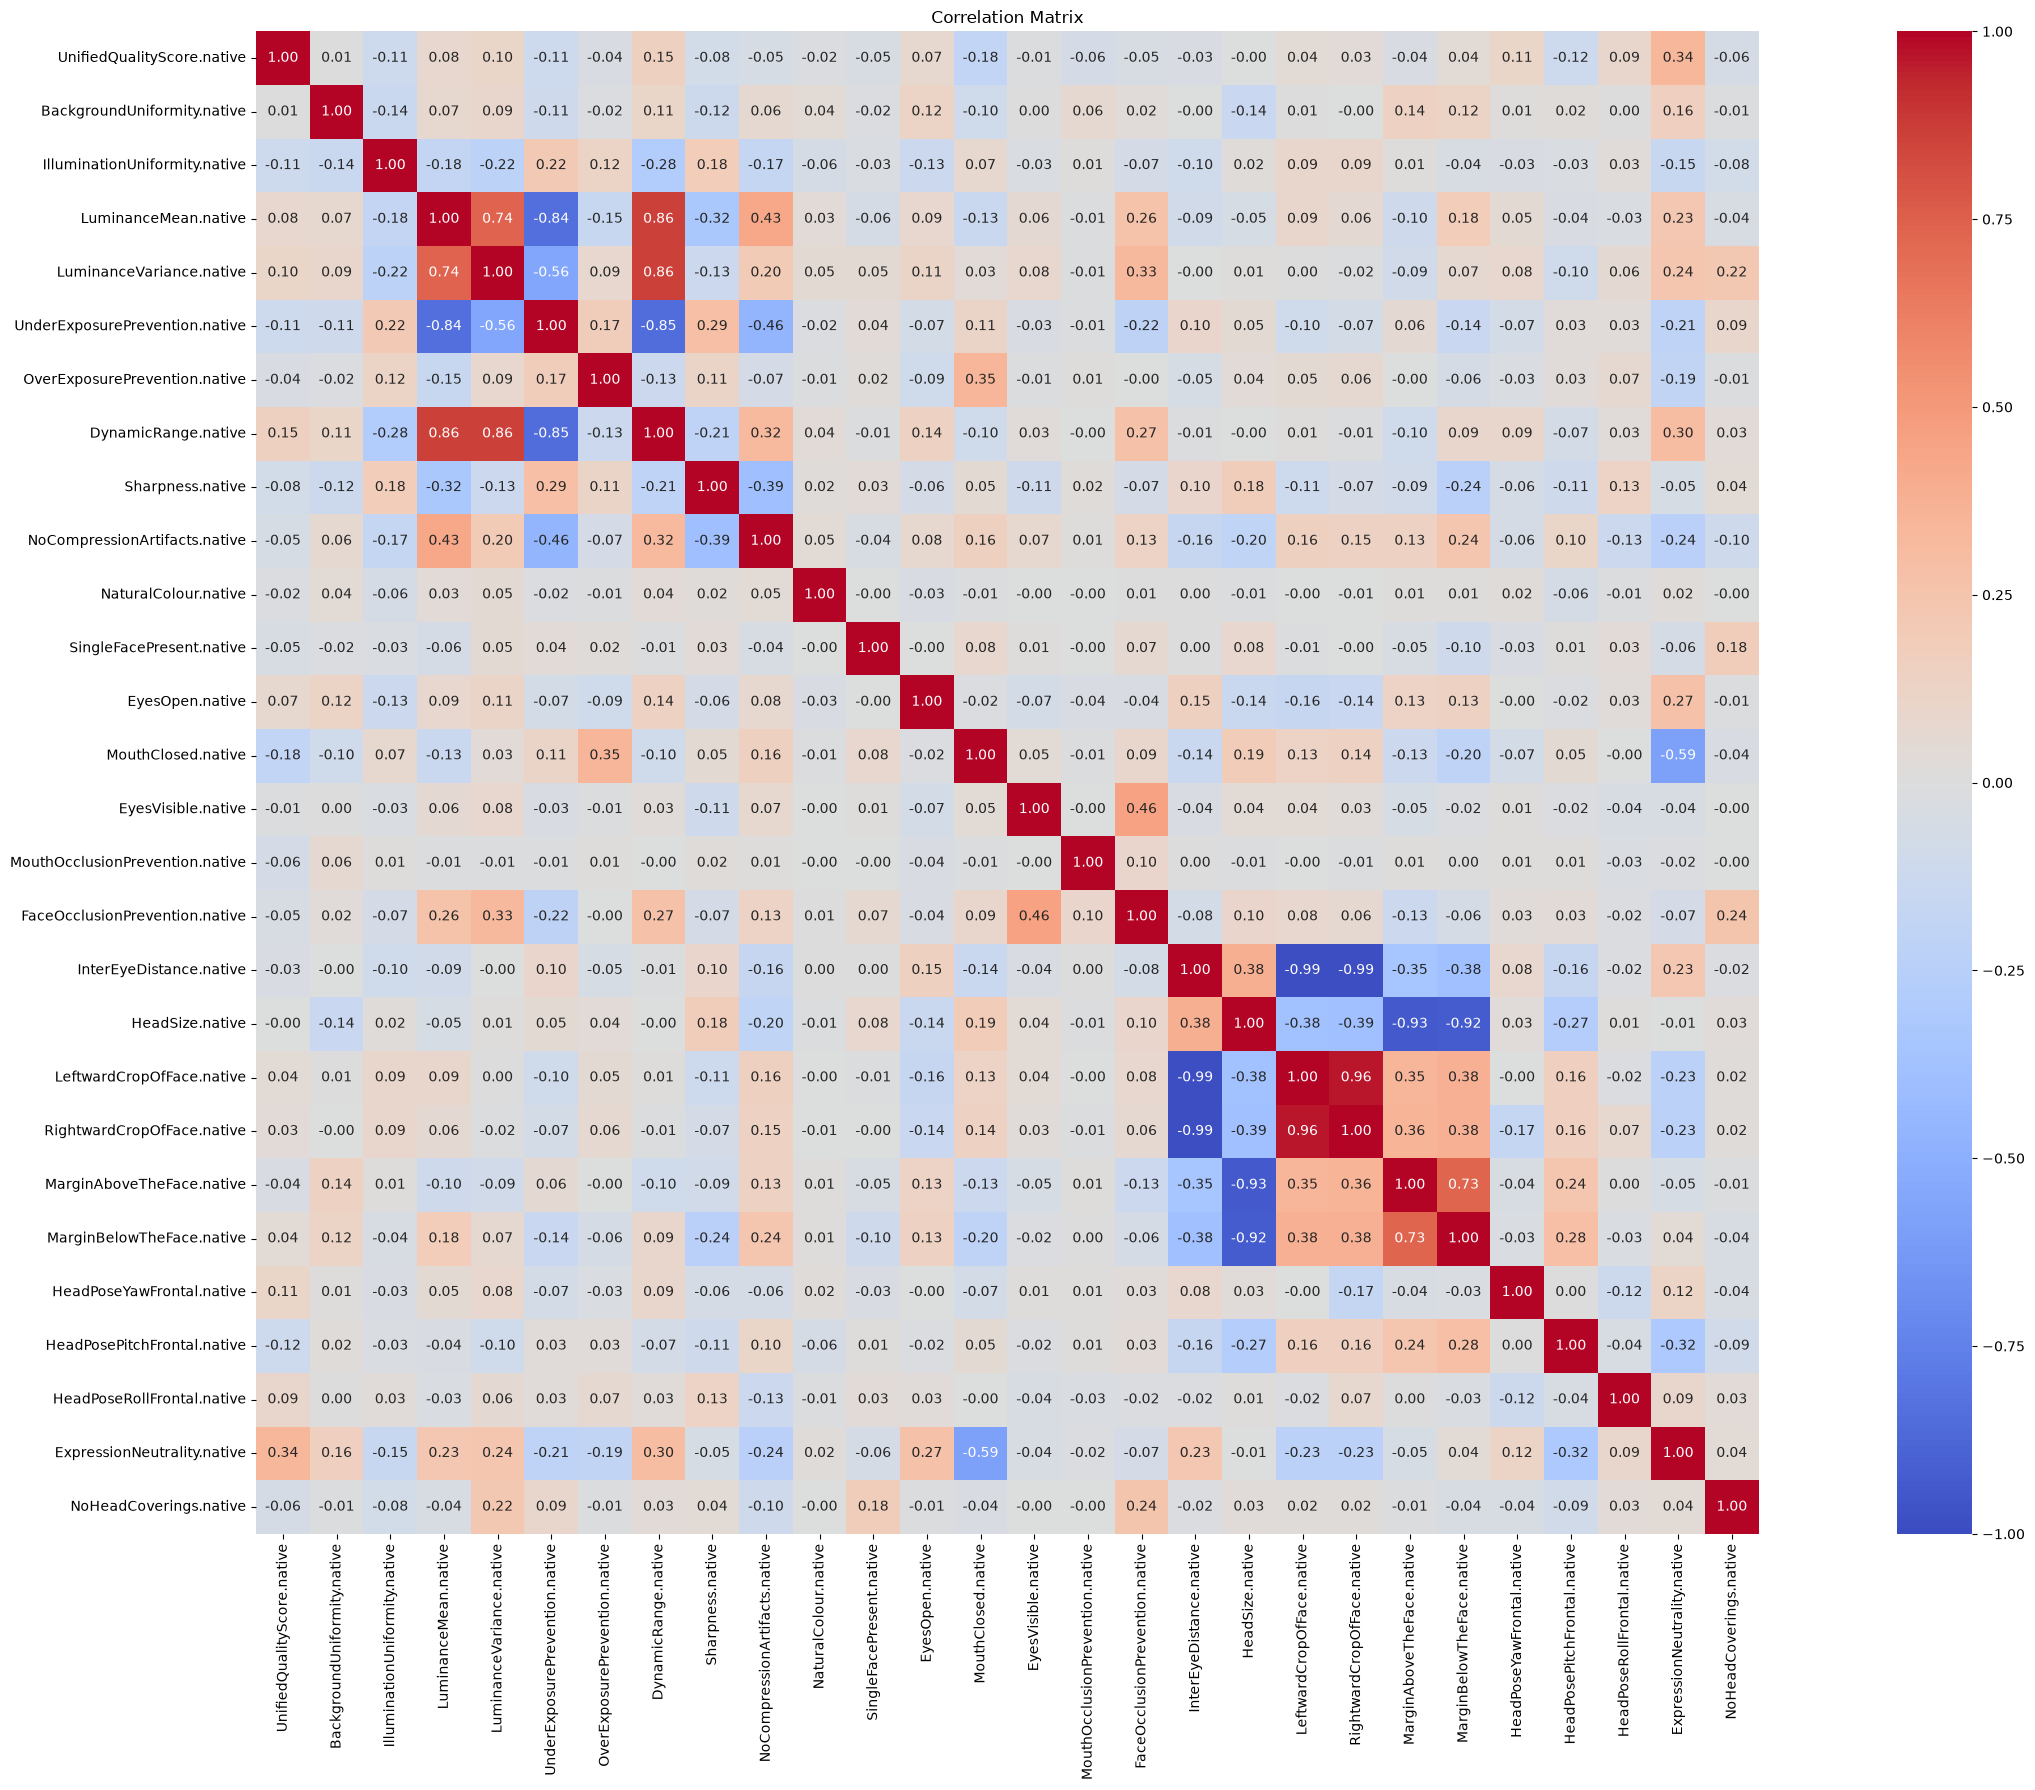

In [20]:
num_df = native.select(cs.numeric())
corr_df = num_df.corr()

corr_pd = corr_df.to_pandas()
corr_pd.index = corr_pd.columns   # le righe prendono i nomi delle colonne

plt.figure(figsize=(28, 18))
sns.heatmap(
    corr_pd,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    square=True,
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [21]:
def _values(df, col):
    s = df[col]
    arr = s.to_numpy() if hasattr(s, "to_numpy") else np.asarray(s)
    x = np.asarray(arr, dtype=float)
    x = x[~np.isnan(x)]
    return x[x != -1]                                  # scarta i codici di errore


def hist_df(df, cols=None, percentili=(5, 10, 25, 50, 75), bins=40,
            clip=None, log_y=False, n_col=4):
    if cols is None:
        cols = [c for c in df.columns if str(c).endswith((".scalar", ".native"))] or list(df.columns)
    n_row = math.ceil(len(cols) / n_col)
    fig, axes = plt.subplots(n_row, n_col, figsize=(5 * n_col, 3.5 * n_row), squeeze=False)
    axes = axes.flatten()
    colori = plt.cm.viridis(np.linspace(0.15, 0.85, len(percentili)))

    for ax, c in zip(axes, cols):
        x = _values(df, c)
        if len(x) == 0:
            ax.set_title(f"{c} (vuota)", fontsize=9)
            continue
        rng = clip if clip is not None else tuple(np.percentile(x, [0, 100]))
        if rng[0] == rng[1]:
            rng = (rng[0] - 0.5, rng[1] + 0.5)
        ax.hist(x, bins=bins, range=rng, edgecolor="white", linewidth=0.4, color="#4C78A8")
        for p, q, col in zip(percentili, np.percentile(x, percentili), colori):
            ax.axvline(q, color=col, linestyle="--", linewidth=1.4, label=f"P{p}={q:.2f}")
        if log_y:
            ax.set_yscale("log")
        ax.set_title(str(c), fontsize=9)
        ax.legend(fontsize=7)

    for ax in axes[len(cols):]:
        ax.set_visible(False)
    fig.tight_layout()
    return fig

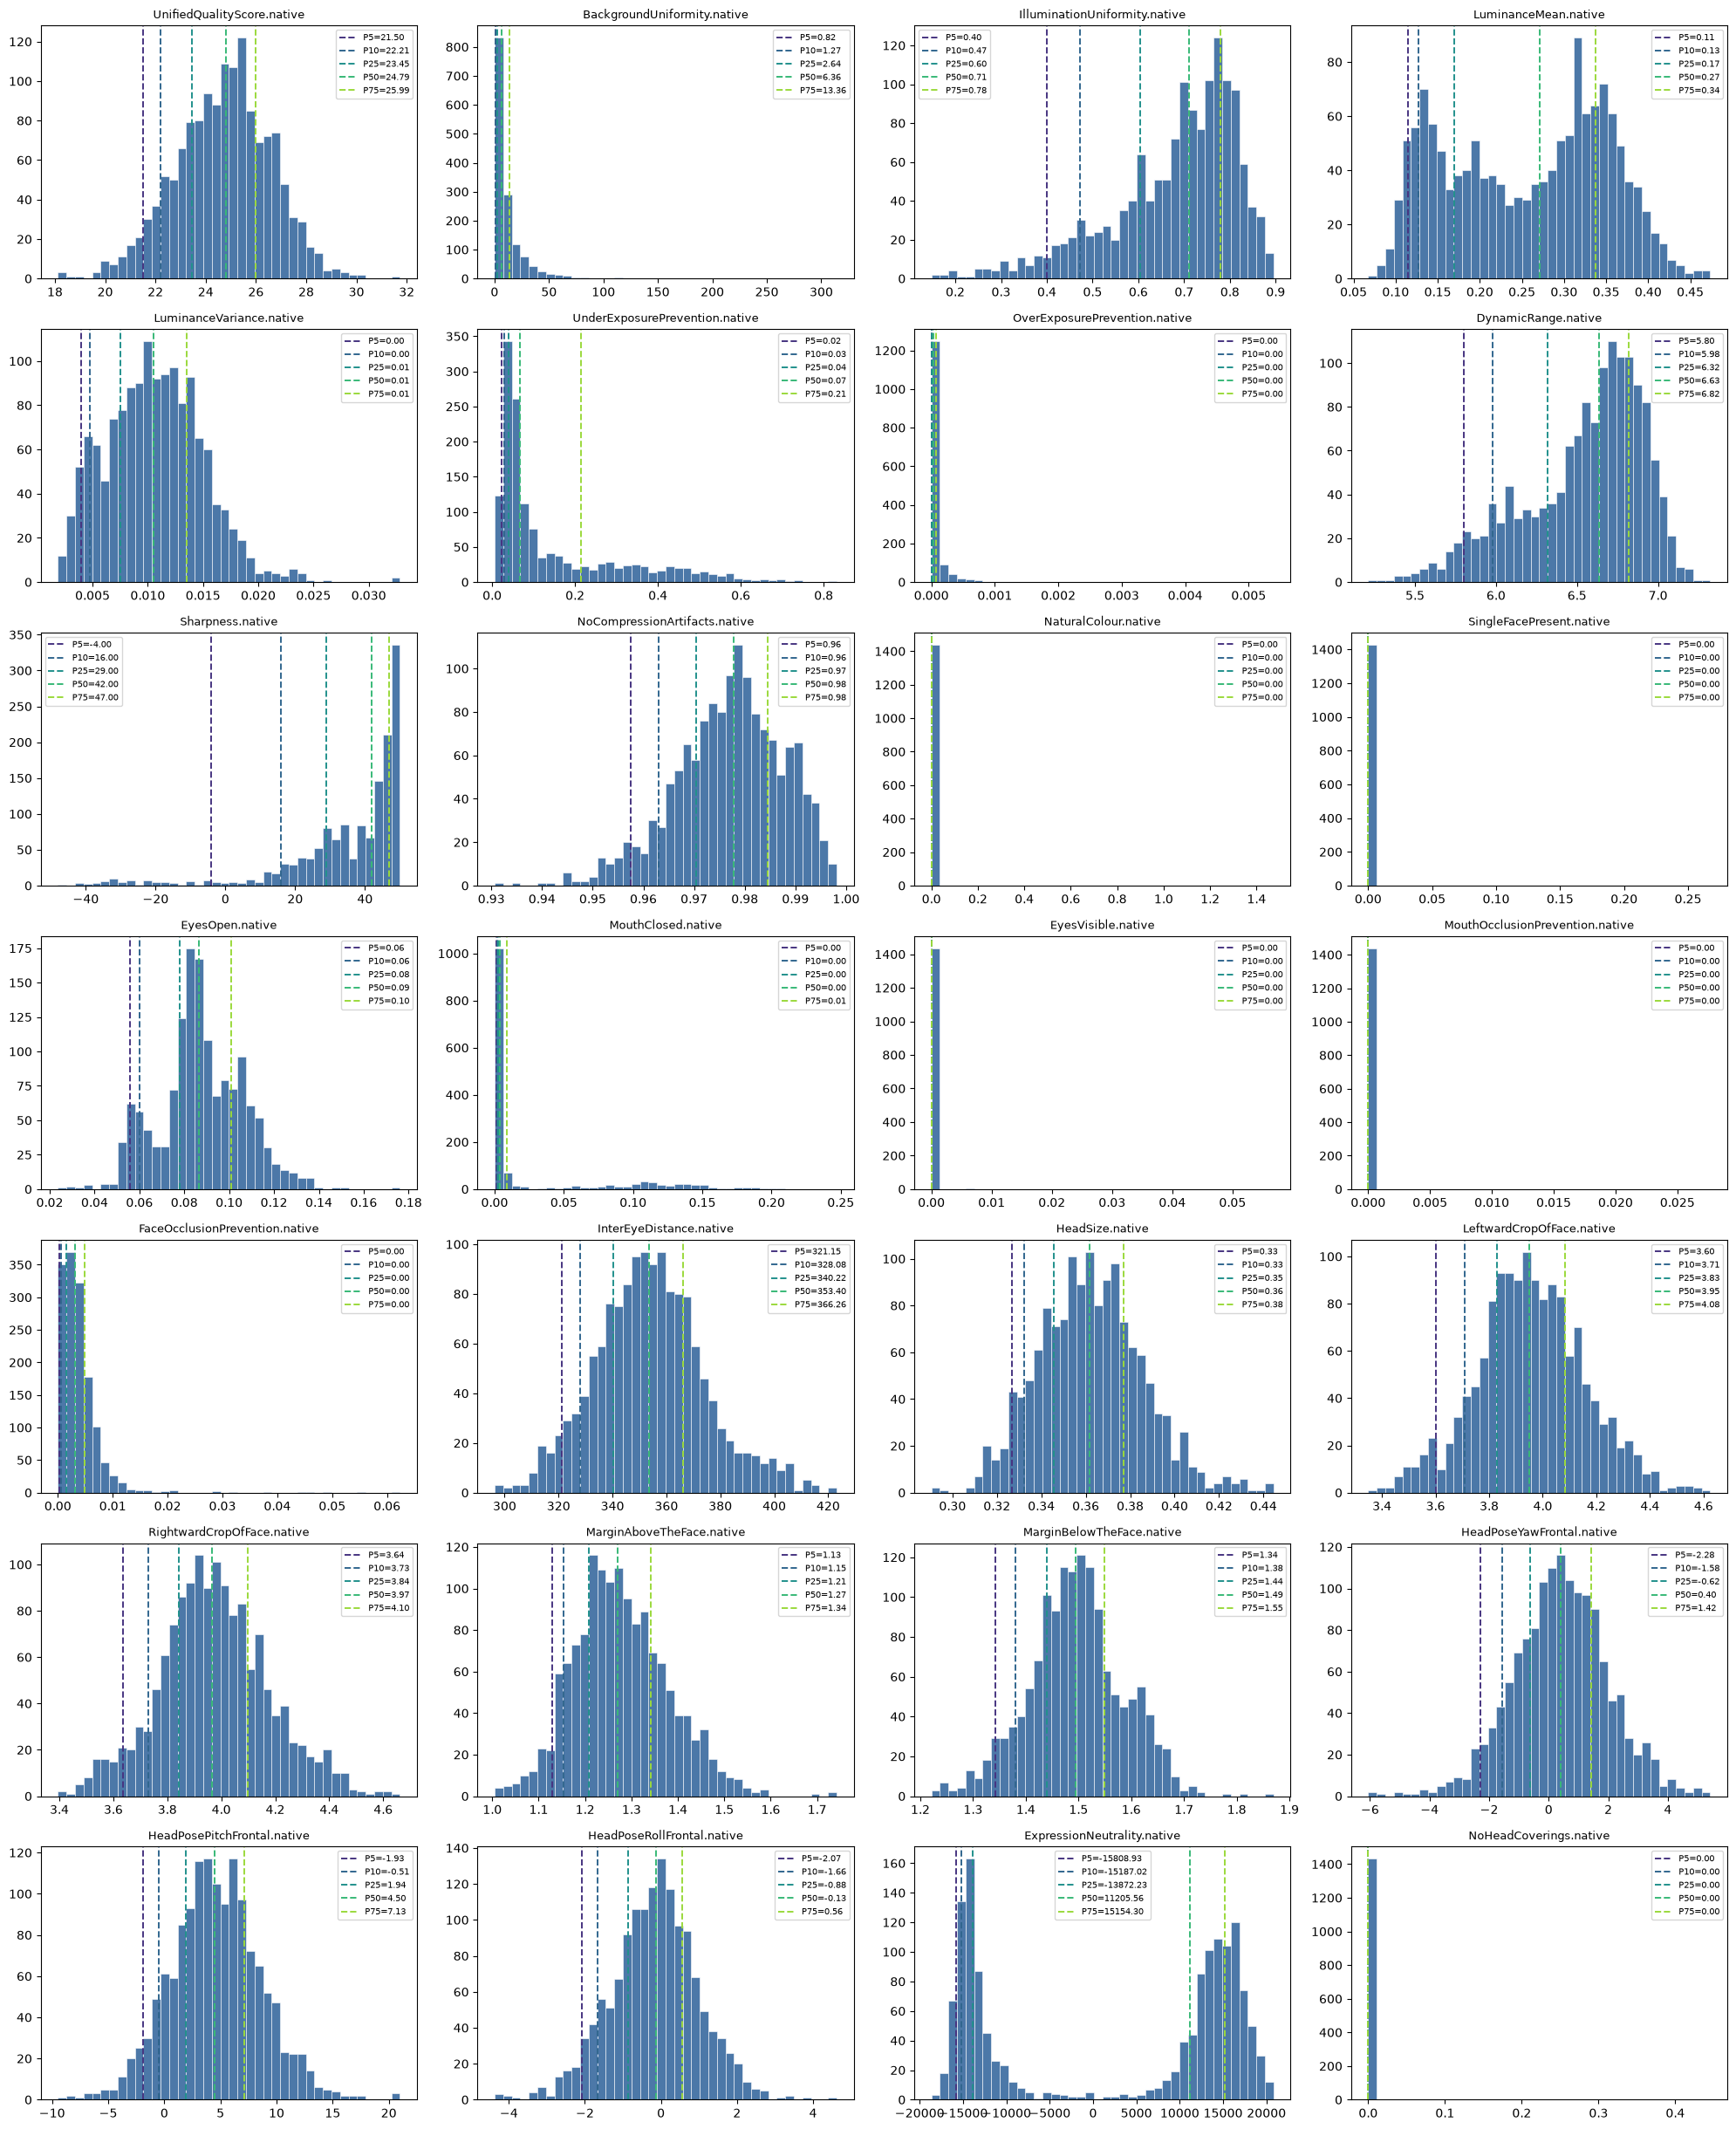

In [22]:
fig = hist_df(native);

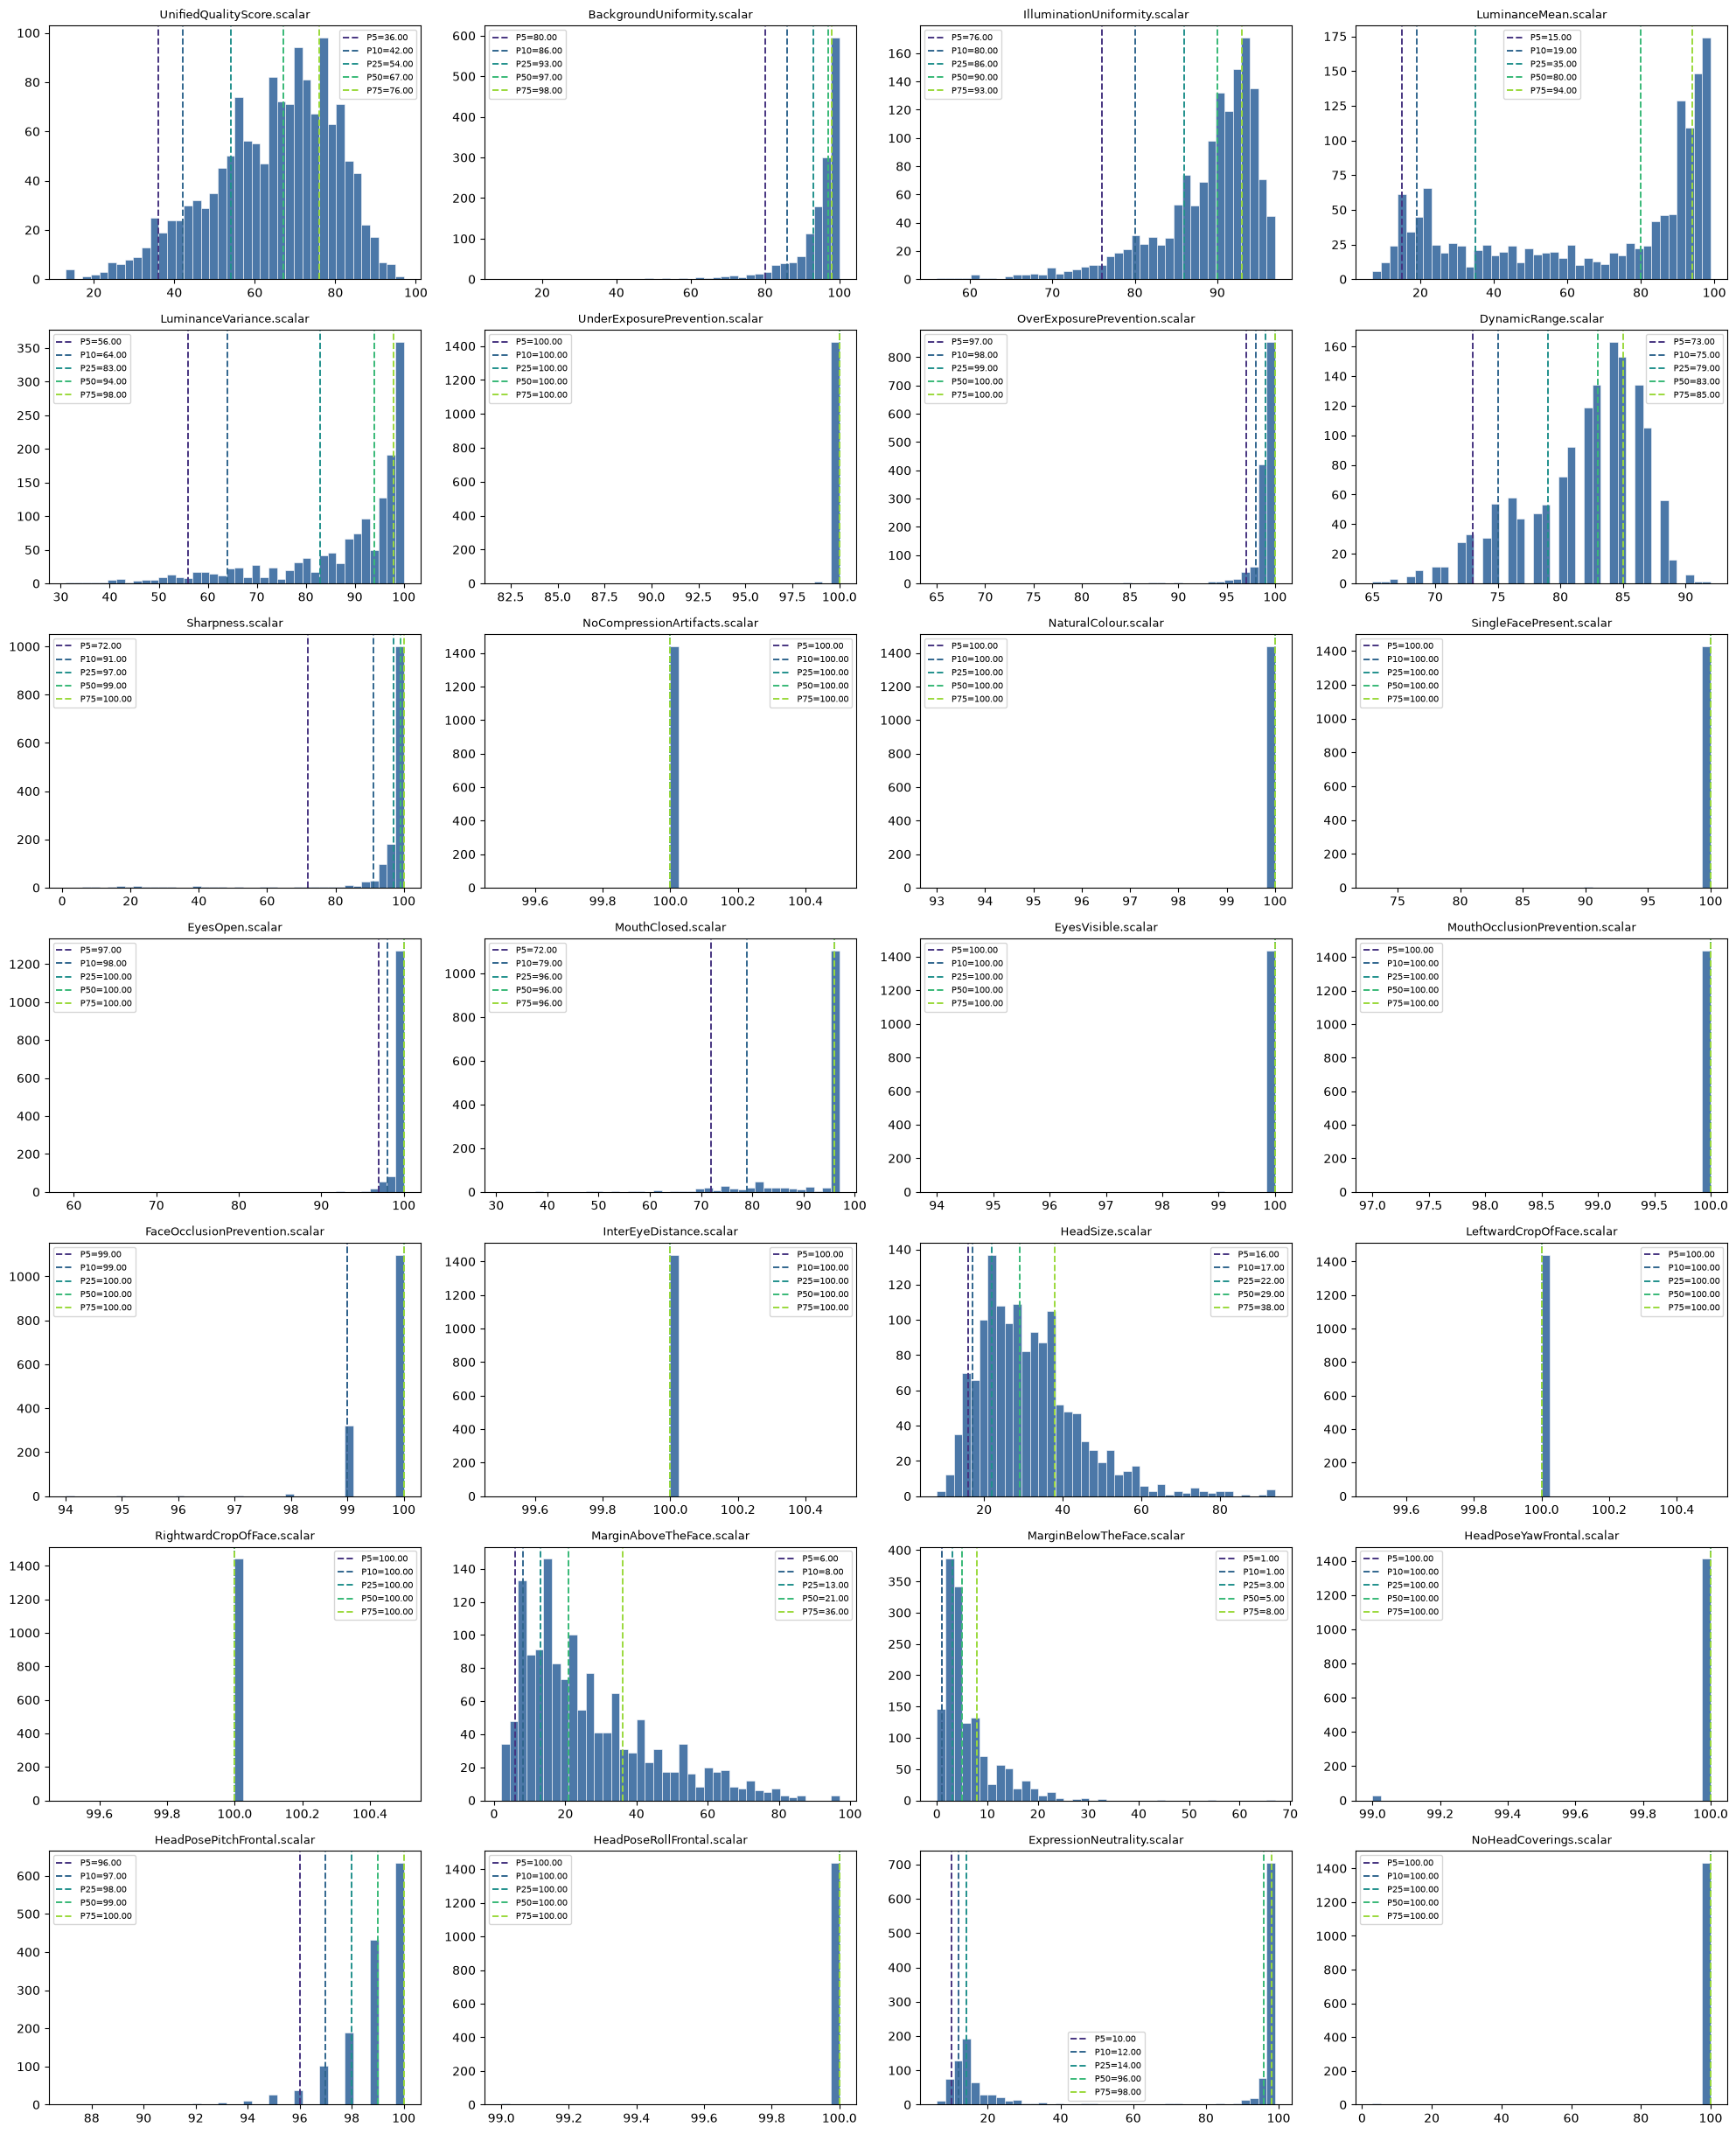

In [23]:
fig = hist_df(scalar);

In [24]:
prompt_path = Path('../data/cfd/prompt/prompt_cfd_soglie_glint.csv')
prompt = pl.read_csv(
    prompt_path,
    separator=','
)
pl.Config.set_fmt_str_lengths(1000)
pl.Config.set_tbl_cols(-1)


prompt

file,split,issues,good,issues_list,good_list,prompt
str,str,str,str,str,str,str
"""CFD-BF-009-006-HO.jpg""","""test""","""partial head covering; cluttered, non-uniform background; image clearly too dark or too bright; head too small in the frame""","""eyes open; even lighting on the face; proper space above the head; proper space below the face""","""[""partial head covering"", ""cluttered, non-uniform background"", ""image clearly too dark or too bright"", ""head too small in the frame""]""","""[""eyes open"", ""even lighting on the face"", ""proper space above the head"", ""proper space below the face""]""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: partial head covering; cluttered, non-uniform background; image clearly too dark or too bright; head too small in the frame Good aspects: eyes open; even lighting on the face; proper space above the head; proper space below the face"""
"""CFD-BM-011-017-HO.jpg""","""test""","""partial head covering; cluttered, non-uniform background; image clearly too dark or too bright; head too small in the frame""","""eyes open; even lighting on the face; proper space above the head; proper space below the face""","""[""partial head covering"", ""cluttered, non-uniform background"", ""image clearly too dark or too bright"", ""head too small in the frame""]""","""[""eyes open"", ""even lighting on the face"", ""proper space above the head"", ""proper space below the face""]""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: partial head covering; cluttered, non-uniform background; image clearly too dark or too bright; head too small in the frame Good aspects: eyes open; even lighting on the face; proper space above the head; proper space below the face"""
"""CFD-BM-022-027-HO.jpg""","""test""","""eyes closed or mostly closed; partial head covering; cluttered, non-uniform background; image clearly too dark or too bright; head too small in the frame""","""even lighting on the face; proper space above the head; proper space below the face""","""[""eyes closed or mostly closed"", ""partial head covering"", ""cluttered, non-uniform background"", ""image clearly too dark or too bright"", ""head too small in the frame""]""","""[""even lighting on the face"", ""proper space above the head"", ""proper space below the face""]""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; partial head covering; cluttered, non-uniform background; image clearly too dark or too bright; head too small in the frame Good aspects: even lighting on the face; proper space above the head; proper space below the face"""
"""CFD-BF-029-005-HO.jpg""","""test""","""partial head covering; cluttered, non-uniform background; image clearly too dark or too bright; head too small in the frame""","""eyes open; even lighting on the face; proper space above the head; proper space below the face""","""[""partial head covering"", ""cluttered, non-uniform background"", ""image clearly too dark or too bright"", ""head too small in the frame""]""","""[""eyes open"", ""even lighting on the face"", ""proper space above the head"", ""proper space below the face""]""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: partial head covering; cluttered, non-uniform background; image clearly too dark or too bright; head too small in the frame Good aspects: eyes open; even lighting on the face; proper space above the head; proper space below the face"""
"""CFD-WF-005-027-F.jpg""","""test""","""partial head covering; cluttered, non-uniform background; head too small in the frame""","

In [25]:
import base64, html, io
from pathlib import Path

import polars as pl
from PIL import Image
from IPython.display import HTML, display


def mostra_tabella(df, shards_dir, cols=None, n=5, files=None, seed=0, width=110, file_col="file"):
    """Una riga per immagine: miniatura + le colonne del DataFrame.
    df         : DataFrame con una colonna 'file' (nome dell'immagine) e le altre colonne da mostrare
    shards_dir : cartella che contiene shard_00000, shard_00001, ...
    cols       : colonne da mostrare (default: tutte tranne 'file' e 'prompt')"""
    index = {p.name: p for p in Path(shards_dir).expanduser().glob("shard_*/*")
             if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".ppm"}}

    if files is None:
        tutti = df[file_col].unique(maintain_order=True)
        files = tutti.sample(min(n, len(tutti)), seed=seed).to_list()
    cols = cols or [c for c in df.columns if c not in (file_col, "prompt")]
    sub = {r[file_col]: r for r in df.filter(pl.col(file_col).is_in(files)).iter_rows(named=True)}

    def miniatura(name):
        if name not in index:
            return "<i>immagine non trovata</i>"
        im = Image.open(index[name]).convert("RGB")
        im.thumbnail((width * 2, width * 3))
        buf = io.BytesIO()
        im.save(buf, "JPEG", quality=80)
        return f'<img src="data:image/jpeg;base64,{base64.b64encode(buf.getvalue()).decode()}" width="{width}">'

    def testo(v):
        if v is None:
            return "-"
        return html.escape("; ".join(map(str, v)) if isinstance(v, list) else str(v))

    righe = []
    for f in files:
        r = sub.get(f, {})
        nome = Path(f).name
        celle = [f"<td>{miniatura(nome)}<br><small>{html.escape(nome)}</small></td>"]
        celle += [f"<td>{testo(r.get(c))}</td>" for c in cols]
        righe.append("<tr>" + "".join(celle) + "</tr>")

    css = ("<style>.tm{border-collapse:collapse;font-size:13px}.tm td,.tm th{border:1px solid #ccc;"
           "padding:6px;vertical-align:top;max-width:260px;word-wrap:break-word;text-align:left}"
           ".tm th{background:#f2f2f2}</style>")
    intest = "".join(f"<th>{html.escape(str(c))}</th>" for c in cols)
    display(HTML(f"{css}<table class='tm'><tr><th>immagine</th>{intest}</tr>" + "".join(righe) + "</table>"))

immagine,split,issues,good,issues_list,good_list
CFD-BM-232-213-N.jpg,test,"partial head covering; cluttered, non-uniform background; image clearly too dark or too bright; head too small in the frame",eyes open; neutral expression; even lighting on the face; proper space above the head; proper space below the face,"[""partial head covering"", ""cluttered, non-uniform background"", ""image clearly too dark or too bright"", ""head too small in the frame""]","[""eyes open"", ""neutral expression"", ""even lighting on the face"", ""proper space above the head"", ""proper space below the face""]"
CFD-IF-608-390-N.jpg,test,partial head covering; slightly uneven background; head too small in the frame,eyes open; neutral expression; even lighting on the face; well exposed image; proper space above the head; proper space below the face,"[""partial head covering"", ""slightly uneven background"", ""head too small in the frame""]","[""eyes open"", ""neutral expression"", ""even lighting on the face"", ""well exposed image"", ""proper space above the head"", ""proper space below the face""]"
CFD-BF-005-001-N.jpg,test,partial head covering; slightly uneven background; image slightly too dark or bright; head too small in the frame,eyes open; neutral expression; even lighting on the face; proper space above the head; proper space below the face,"[""partial head covering"", ""slightly uneven background"", ""image slightly too dark or bright"", ""head too small in the frame""]","[""eyes open"", ""neutral expression"", ""even lighting on the face"", ""proper space above the head"", ""proper space below the face""]"
CFD-BF-004-009-HO.jpg,test,"eyes partly closed; partial head covering; cluttered, non-uniform background; image clearly too dark or too bright; head too small in the frame",even lighting on the face; proper space above the head; proper space below the face,"[""eyes partly closed"", ""partial head covering"", ""cluttered, non-uniform background"", ""image clearly too dark or too bright"", ""head too small in the frame""]","[""even lighting on the face"", ""proper space above the head"", ""proper space below the face""]"
CFD-BF-002-006-HC.jpg,test,"partial head covering; cluttered, non-uniform background; image clearly too dark or too bright; head too small in the frame",eyes open; even lighting on the face; proper space above the head; proper space below the face,"[""partial head covering"", ""cluttered, non-uniform background"", ""image clearly too dark or too bright"", ""head too small in the frame""]","[""eyes open"", ""even lighting on the face"", ""proper space above the head"", ""proper space below the face""]"
CFD-BM-028-028-HO.jpg,test,"eyes partly closed; partial head covering; cluttered, non-uniform background; image clearly too dark or too bright; head too small in the frame",even lighting on the face; proper space above the head; proper space below the face,"[""eyes partly closed"", ""partial head covering"", ""cluttered, non-uniform background"", ""image clearly too dark or too bright"", ""head too small in the frame""]","[""even lighting on the face"", ""proper space above the head"", ""proper space below the face""]"
CFD-LF-220-120-N.jpg,test,"partial head covering; cluttered, non-uniform background; head too small in the frame",eyes open; neutral expression; even lighting on the face; well exposed image; proper space above the head; proper space below the face,"[""partial head covering"", ""cluttered, non-uniform background"", ""head too small in the frame""]","[""eyes open"", ""neutral expression"", ""even lighting on the face"", ""well exposed image"", ""proper space above the head"", ""proper space below the face""]"
CFD-BF-007-004-HO.jpg,test,eyes partly closed; partial head covering; slightly uneven background; image slightly too dark or bright; head too small in the frame,even lighting on the face; proper space above the head; proper space below the face,"[""eyes partly closed"", ""partial head covering"", ""slig
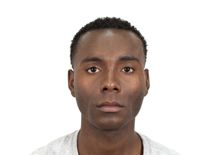
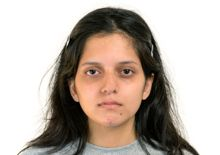
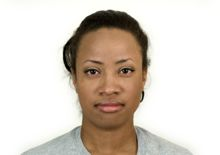
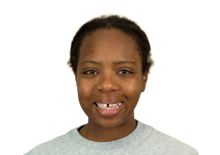
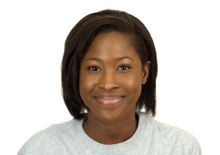
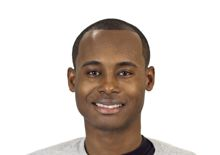
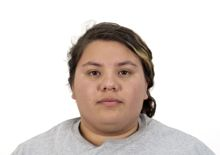
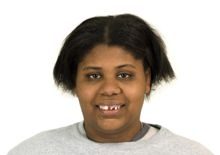
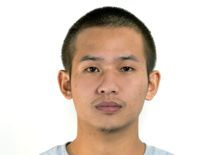
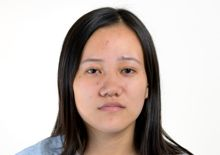
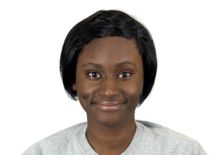
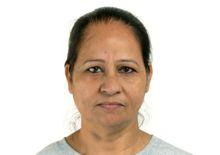
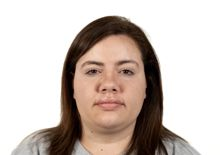
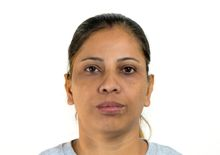
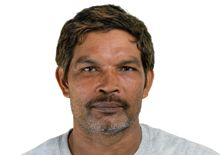
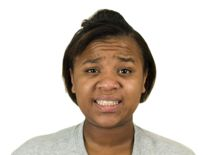
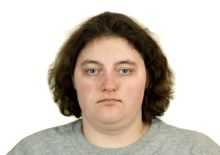
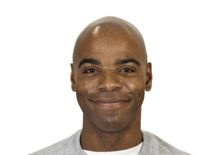
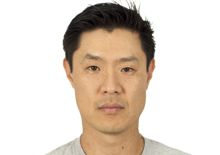
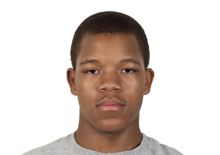

In [28]:
mostra_tabella(prompt, "~/prove/cfd_all/images", n=20)    